<a href="https://colab.research.google.com/github/aldo02032004/environmental-issue-monitoring/blob/main/environmental-issue-monitoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pipeline: ingest Excel -> cleaning teks -> klasifikasi isu & lokasi ->
          dashboard peta + bar chart -> tabel top isu per pulau/media sosial.

Library eksternal utama:
  - pandas / geopandas   : manipulasi data & geometri peta
  - matplotlib           : semua chart & peta choropleth
  - requests             : download file Excel & GeoJSON
  - flashtext (dipakai di dalam `great.geo`, bukan langsung di sini)

Library `great` (publik, di-install dari github.com/azmkto/GREAT-Tools):
  - PROVINCE_FIX   : kamus normalisasi ejaan nama provinsi (62 entri: "Sumut" -> "Sumatera Utara", dst)
  - GEO_FIX        : sama seperti PROVINCE_FIX tapi khusus untuk nama provinsi versi GeoJSON
  - PULAU_MAP      : provinsi -> pulau
  - ISLAND_ORDER   : urutan pulau standar untuk chart
  - classify_issue : klasifikasi isu lingkungan dari teks (aturan ada di ISSUE_RULES, internal)
  - resolve_frame  : deteksi Provinsi + Pulau dari teks bebas (great/geo.py).
                      Ini resolver resmi — gabungan gazetteer ~1500 nama tempat +
                      data resmi BPS kabupaten/kota + disambiguasi nama ambigu.
  - normalize_slang: normalisasi kata slang/typo sebelum klasifikasi isu.
                      DIPAKAI KHUSUS untuk `search_text` (klasifikasi isu), BUKAN
                      untuk deteksi lokasi — `resolve_frame` jalan di atas
                      `clean_text` yang belum kena normalize_slang, supaya nama
                      tempat tidak berisiko ikut ter-substitusi oleh kamus slang.

# CELL 1 — SETUP: install `great` + dependency, import
Install library (sekitar 1 menit di Colab). Output: lokasi library `great` dan jumlah entri kamus ejaan provinsi.

In [1]:
%pip install -q "great[text,geo] @ git+https://github.com/azmkto/GREAT-Tools.git" matplotlib openpyxl tqdm

In [2]:
import os
import re
import html
import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from io import BytesIO
from collections import Counter
from shapely.geometry import MultiPolygon
from tqdm.auto import tqdm
from IPython.display import display

from great import PROVINCE_FIX, PULAU_MAP, GEO_FIX, ISLAND_ORDER, classify_issue
from great.geo import resolve_frame          # resolver lokasi resmi, lihat docstring di atas
from great.text import normalize_slang       # normalisasi slang untuk klasifikasi isu

tqdm.pandas()

print("Jumlah entri PROVINCE_FIX (fix ejaan, bukan gazetteer):", len(PROVINCE_FIX))

Jumlah entri PROVINCE_FIX (fix ejaan, bukan gazetteer): 62


# CELL 2 — INGESTI DATA DARI EXCEL
Isi `SOURCE` dengan link Google Sheets/Drive (*Anyone with the link*) atau path `.xlsx`. Output: nama sheet yang dipakai, ukuran data, dan 5 baris pertama.

In [3]:
def resolve_xlsx_url(source: str) -> str:
    """Ubah link Google Sheets/Drive jadi url download .xlsx."""
    sheet_match = re.search(r"docs\.google\.com/spreadsheets/d/([a-zA-Z0-9-_]+)", source)
    drive_match = re.search(r"drive\.google\.com/file/d/([a-zA-Z0-9-_]+)", source)
    if sheet_match:
        return f"https://docs.google.com/spreadsheets/d/{sheet_match.group(1)}/export?format=xlsx"
    if drive_match:
        return f"https://drive.google.com/uc?export=download&id={drive_match.group(1)}"
    return source  # sudah berupa path/url .xlsx


def _download_bytes(url: str) -> BytesIO:
    # Google kadang balas 400/5xx sesaat, jadi coba ulang beberapa kali sebelum menyerah
    for attempt in range(1, 4):
        resp = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, allow_redirects=True)
        if resp.ok:
            break
        time.sleep(3 * attempt)
    resp.raise_for_status()
    content_type = resp.headers.get("Content-Type", "")
    if "html" in content_type.lower():
        raise ValueError(
            "Gagal download file asli (dapat HTML, bukan xlsx). "
            "Pastikan akses file/sheet sudah 'Anyone with the link'."
        )
    return BytesIO(resp.content)


def _find_best_sheet(xls: pd.ExcelFile, expected_cols: list, skiprows: int):
    """Cari sheet yang headernya paling cocok dengan expected_cols."""
    best_sheet, best_match = xls.sheet_names[0], -1
    for name in xls.sheet_names:
        try:
            preview = pd.read_excel(xls, sheet_name=name, skiprows=skiprows, nrows=0)
            preview.columns = [c.strip() for c in preview.columns]
            match_count = sum(c in preview.columns for c in expected_cols)
            if match_count > best_match:
                best_match, best_sheet = match_count, name
        except Exception:
            continue
    return best_sheet


def load_raw_data(source: str, sheet_name=None, skiprows: int = 1) -> pd.DataFrame:
    url = resolve_xlsx_url(source)
    file_obj = _download_bytes(url) if url.startswith("http") else url
    xls = pd.ExcelFile(file_obj)

    expected_cols = ["No", "Headline", "Mentions", "Date", "Link", "Sentiment", "Author"]

    if sheet_name is None:
        sheet_name = _find_best_sheet(xls, expected_cols, skiprows)
        print(f"[INFO] Menggunakan sheet: '{sheet_name}'")

    df = pd.read_excel(xls, sheet_name=sheet_name, skiprows=skiprows)
    df.columns = [c.strip() for c in df.columns]

    missing = [c for c in expected_cols if c not in df.columns]
    if missing:
        print(f"[WARNING] Kolom hilang: {missing}")

    df = df.dropna(subset=["Mentions"]).reset_index(drop=True) if "Mentions" in df.columns else df
    available_cols = [c for c in expected_cols if c in df.columns]
    return df[available_cols]


SOURCE = "https://docs.google.com/spreadsheets/d/119b-k0DDykSpZJ-BAmIANWKnlfYLBfho/edit?usp=sharing&ouid=114059382170725404105&rtpof=true&sd=true"

df_raw = load_raw_data(SOURCE)
print(f"Data berhasil dimuat: {df_raw.shape}")
display(df_raw.head())


[INFO] Menggunakan sheet: 'Sheet1'


Data berhasil dimuat: (1826, 7)


,No,Headline,Mentions,Date,Link,Sentiment,Author
0,1,NaN,"RT setelah dua tahun menjabat, sekarang syarat...",2026-09-23 15:48:42,https://twitter.com/web/statuses/2102681553247...,Negative,@aurorineryu_
1,2,Yusril Sebut Pemerintah Persilakan KPK Jika In...,"Menurut Yusril, KPK adalah lembaga independen ...",2026-09-23 15:21:03,https://news.republika.co.id/berita/tlt5v3409/...,Negative,news.republika.co.id
2,3,Kantor BPN Kota Mojokerto Ikut Digeledah KPK,"Juru Bicara KPK, Budi Prasetyo. (Foto: Dokumen...",2026-09-23 15:20:00,https://rmol.id/hukum/read/2026/09/23/722678/k...,Negative,rmol.id
3,4,450 Ribu Orang Diprediksi Meninggal karena Suh...,Warga mengisi air bersih yang disediakan BPBD ...,2026-09-23 15:15:41,https://www.cnbcindonesia.com/lifestyle/202609...,Negative,www.cnbcindonesia.com
4,5,"VIDEO: Hujan Guyur Palembang, Kabut Asap Mulai...","Kabut asap juga menyelimuti Kota Palembang, im...",2026-09-23 15:15:15,https://www.cnnindonesia.com/tv/20260923134256...,Negative,www.cnnindonesia.com


# CELL 3 — DATA CLEANING
Buang boilerplate berita, URL, hashtag, mention, teks terlalu pendek, dan berita yang di-syndicate ulang. Output: jumlah baris sebelum → sesudah dedup.

In [4]:
URL_PATTERN = re.compile(r'https?://\S+|www\.\S+')
HASHTAG_PATTERN = re.compile(r'#\S+')
MENTION_PATTERN = re.compile(r'@\S+')

# Boilerplate baku yang sering nempel di berita/postingan (disclaimer, ajakan subscribe, dsb)
BOILERPLATE_PATTERNS = [
    r"Dilarang keras mengambil konten.*?ANTARA\.",
    r"Kirim\s*Komentar menjadi tanggung-?jawab Anda sesuai UU ITE\.",
    r"Yuk Subscribe.*?(?=\n\n|\Z)",
    r"Follow (WA Channel|our Official).*?(?=\n\n|\Z)",
    r"Like our Official Facebook.*?(?=\n\n|\Z)",
    r"Uploader\s*:\s*\S+",
    r"Tanggal Tayang\s*:.*",
    r"Selengkapnya baca di\s*:\s*\S+",
]
BOILERPLATE_RE = re.compile("|".join(BOILERPLATE_PATTERNS), flags=re.IGNORECASE | re.DOTALL)


def clean_text(raw_text: str) -> str:
    if not isinstance(raw_text, str):
        return ""
    text = html.unescape(raw_text)
    text = BOILERPLATE_RE.sub(" ", text)
    text = URL_PATTERN.sub(" ", text)
    text = HASHTAG_PATTERN.sub(" ", text)
    text = MENTION_PATTERN.sub(" ", text)
    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r'\n{2,}', '\n', text)
    return text.strip()


df_clean = df_raw.copy()

print("[INFO] Membersihkan teks...")
df_clean["clean_text"] = df_clean["Mentions"].progress_apply(clean_text)
df_clean = df_clean[df_clean["clean_text"].str.len() > 20].reset_index(drop=True)

df_clean["doc_id"] = [f"DOC-{i:05d}" for i in range(len(df_clean))]

# Dedup berdasarkan headline + 200 karakter awal clean_text (cukup buat nangkap
# berita/posting yang di-syndicate ulang tanpa perlu bandingin teks penuh)
df_clean["dedupe_key"] = (
    df_clean["Headline"].astype(str).str.strip().str.lower() + "||" +
    df_clean["clean_text"].astype(str).str[:200].str.strip().str.lower()
)
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset="dedupe_key", keep="first").reset_index(drop=True)
print(f"[INFO] Dedup: {before} -> {len(df_clean)} baris")
df_clean = df_clean.drop(columns="dedupe_key")

df_clean["clean_text"] = df_clean["clean_text"].str.lower()
df_clean["search_text"] = (
    df_clean["Headline"].str.lower().fillna("") + " " + df_clean["clean_text"].fillna("")
)

# search_text dipakai KHUSUS untuk klasifikasi isu (classify_issue), bukan untuk
# deteksi lokasi. resolve_frame nanti baca clean_text yang belum kena normalize_slang.
print("[INFO] Normalisasi slang...")
df_clean["search_text"] = df_clean["search_text"].progress_apply(normalize_slang)


[INFO] Membersihkan teks...


[INFO] Dedup: 1825 -> 532 baris
[INFO] Normalisasi slang...


# CELL 4 — KLASIFIKASI ISU & DETEKSI LOKASI
Setiap dokumen diberi **isu** (`classify_issue`), **provinsi + pulau** (`resolve_frame`), dan **tipe link** (berita / media sosial). Berita luar negeri yang tidak menyebut Indonesia ditandai *Noise*. Output: statistik isu, sebaran pulau, tipe link, dan tabel jumlah isu per provinsi (dokumen yang hanya menyebut nama pulau dibagi proporsional ke provinsi di pulau itu).

In [5]:
def distribute_ambiguous_locations(df: pd.DataFrame) -> Counter:
    """Distribusikan dokumen berlabel 'Provinsi Tidak Spesifik' (cuma nama pulau
    yang kesebut, provinsi-nya tidak) secara proporsional ke provinsi-provinsi
    di pulau itu, berbobot jumlah dokumen yang provinsinya sudah pasti."""
    specific = df[~df["Provinsi"].isin(["General Seluruh Indonesia", "Provinsi Tidak Spesifik"])]
    if specific.empty:
        return Counter()

    prov_counts = specific.groupby(["Pulau", "Provinsi"]).size()

    ambiguous = df[df["Provinsi"] == "Provinsi Tidak Spesifik"]
    ambiguous_counts_per_pulau = ambiguous.groupby("Pulau").size()

    extra_counts = Counter()
    for pulau, amb_count in ambiguous_counts_per_pulau.items():
        if pulau not in prov_counts.index.get_level_values(0):
            continue

        prov_weights = prov_counts.loc[pulau]
        proportions = prov_weights / prov_weights.sum()
        raw = proportions * amb_count
        floor_vals = raw.apply(int)
        remainder = int(amb_count - floor_vals.sum())

        # sisa pembulatan dikasih ke provinsi dengan sisa desimal terbesar
        order = (raw - floor_vals).sort_values(ascending=False).index
        alloc = floor_vals.copy()
        for prov in order[:remainder]:
            alloc[prov] += 1

        for prov, add in alloc.items():
            extra_counts[prov] += int(add)

    return extra_counts


SOCIAL_MEDIA_DOMAINS = [
    "facebook.com", "fb.watch", "instagram.com", "twitter.com", "x.com",
    "tiktok.com", "youtube.com", "youtu.be", "threads.net", "linkedin.com",
    "telegram.org", "t.me", "reddit.com",
]


def classify_link_type(link: str) -> str:
    """Klasifikasi tautan ke kategori Berita atau Media Sosial."""
    link_str = str(link).lower()
    if any(domain in link_str for domain in SOCIAL_MEDIA_DOMAINS):
        return "Media Sosial"
    if link_str.startswith("http"):
        return "Berita"
    return "Tidak Diketahui"


MEDIA_MAP = {
    "detikcom": "Detik.com", "detik": "Detik.com",
    "kompas": "Kompas.com", "kompascom": "Kompas.com",
    "liputan6": "Liputan6.com", "liputan 6": "Liputan6.com",
    "tribunnews": "Tribunnews.com", "tribun": "Tribunnews.com",
    "antaranews": "Antara News", "antara": "Antara News",
    "kumparan": "Kumparan.com",
    "suaracom": "Suara.com", "suara": "Suara.com",
    "tempo": "Tempo.co", "tempoco": "Tempo.co",
    "merdekacom": "Merdeka.com", "merdeka": "Merdeka.com",
    "vivanews": "Viva.co.id", "vivacoid": "Viva.co.id",
    "okezone": "Okezone.com",
    "sindonews": "Sindonews.com",
}

if "Media" in df_clean.columns:
    df_clean["Media"] = df_clean["Media"].replace(MEDIA_MAP)

n_docs = len(df_clean)
print(f"[INFO] Memproses {n_docs} dokumen...")

# A. Klasifikasi Isu Inti
t0 = time.time()
df_clean["Isu_Inti"] = df_clean["search_text"].progress_apply(classify_issue)
print(f"[INFO] Klasifikasi isu selesai dalam {time.time() - t0:.2f} detik")

# B. Ekstraksi Lokasi & Pulau — resolver resmi great.geo (bukan gazetteer manual)
t0 = time.time()
df_clean[["Provinsi", "Pulau"]] = resolve_frame(
    df_clean,
    location_col="Location",
    text_cols=("Headline", "clean_text"),
)

# Rename label bawaan library ("Tidak Terdeteksi") -> istilah laporan sendiri
df_clean["Provinsi"] = df_clean["Provinsi"].replace("Tidak Terdeteksi", "General Seluruh Indonesia")
df_clean["Pulau"] = df_clean["Pulau"].replace("Tidak Terdeteksi", "General Seluruh Indonesia")
FOREIGN_NOISE_KEYWORDS = [
    # kota/situs Iran-Israel yang belum ke-cover
    "dimona", "arad", "alborz", "isfahan", "karaj", "kangan",
    "nesher", "haifa", "minab", "negev", "beirut", "hizbullah",
    # Kuba
    "havana",
    # negara/kota lain yang muncul di konteks non-Indonesia
    "filipina", "jepang", "tokyo", "india", "new delhi",
    "china", "tiongkok", "beijing", "qingdao",
     # AS
    "spokane", "washington", "british columbia", "vancouver island", "port alberni",
    # Aljazair
    "aljazair", "aljir", "jijel",
    # China
    "henan", "yunnan", "zhejiang", "jiangsu", "wuxi", "luohe",
    # Korea Selatan
    "gyeongsang",
    # Eropa
    "italia", "verona", "roma", "belanda", "limburg", "amsterdam",
    "yunani", "athena", "megara", "spanyol", "castellon", "avila", "la adrada",
]
FOREIGN_NOISE_PATTERN = re.compile(
    r"\b(" + "|".join(re.escape(k) for k in FOREIGN_NOISE_KEYWORDS) + r")\b",
    re.IGNORECASE,
)

# sinyal domestik: kalau kata "indonesia" ada, jangan override -- bisa aja artikel
# soal sikap/dampak ke Indonesia atas krisis asing, itu tetap relevan.
INDONESIA_SIGNAL_PATTERN = re.compile(r"\bindonesia\b", re.IGNORECASE)

def flag_foreign_noise(row) -> bool:
    if row["Pulau"] != "General Seluruh Indonesia":
        return False  # lokasi Indonesia kedetek -> bukan kandidat noise asing
    text = f"{row.get('Headline', '')} {row.get('clean_text', '')}"
    if not FOREIGN_NOISE_PATTERN.search(text):
        return False
    if INDONESIA_SIGNAL_PATTERN.search(text):
        return False  # nyebut Indonesia -> biarin, jangan override
    return True

noise_mask = df_clean.apply(flag_foreign_noise, axis=1)
n_overridden = int((noise_mask & (df_clean["Isu_Inti"] != "Noise/Tidak Relevan")).sum())
df_clean.loc[noise_mask, "Isu_Inti"] = "Noise/Tidak Relevan"

print(f"[INFO] Geo-gate: {n_overridden} baris di-override jadi 'Noise/Tidak Relevan' "
      f"(dari total {int(noise_mask.sum())} kandidat noise asing terdeteksi)")
print(f"[INFO] Ekstraksi lokasi selesai dalam {time.time() - t0:.2f} detik")

# C. Klasifikasi Tipe Link
if "Link" in df_clean.columns:
    df_clean["Tipe_Link"] = df_clean["Link"].apply(classify_link_type)

# D. Ringkasan Statistik
print("\nSTATISTIK ISU INTI:")
print(df_clean["Isu_Inti"].value_counts())

print("\nSTATISTIK SEBARAN PULAU:")
print(df_clean["Pulau"].value_counts())

if "Tipe_Link" in df_clean.columns:
    print("\nSTATISTIK TIPE LINK:")
    print(df_clean["Tipe_Link"].value_counts())

# E. Rekapitulasi & Distribusi Proporsional Provinsi
extra = distribute_ambiguous_locations(df_clean)

prov_summary = (
    df_clean[~df_clean["Provinsi"].isin(["General Seluruh Indonesia", "Provinsi Tidak Spesifik"])]
    .groupby("Provinsi")
    .size()
    .reset_index(name="Jumlah Isu")
)

extra_df = pd.DataFrame(list(extra.items()), columns=["Provinsi", "Tambahan"])
prov_summary = prov_summary.merge(extra_df, on="Provinsi", how="left")
prov_summary["Tambahan"] = prov_summary["Tambahan"].fillna(0)
prov_summary["Jumlah Isu"] = (prov_summary["Jumlah Isu"] + prov_summary["Tambahan"]).astype(int)

prov_summary = (
    prov_summary.drop(columns="Tambahan")
    .sort_values("Jumlah Isu", ascending=False)
    .reset_index(drop=True)
)

print(f"\n[INFO] Total dokumen tersebar ke {len(prov_summary)} provinsi (setelah distribusi proporsional)")
pd.set_option('display.max_rows', None)
display(prov_summary)

[INFO] Memproses 532 dokumen...


[INFO] Klasifikasi isu selesai dalam 4.75 detik


[INFO] Geo-gate: 2 baris di-override jadi 'Noise/Tidak Relevan' (dari total 2 kandidat noise asing terdeteksi)
[INFO] Ekstraksi lokasi selesai dalam 0.49 detik

STATISTIK ISU INTI:
Isu_Inti
Kebakaran lingkungan         335
Sampah                        31
Konflik agraria               26
Satwa/ekosistem               26
Kekeringan/Krisis Air         23
Pencemaran air/limbah         21
Polusi udara                  17
Banjir/longsor                12
Noise/Tidak Relevan           11
Tambang ilegal/ekstraktif     11
Deforestasi                    5
Energi terbarukan (EBT)        4
Konservasi/reboisasi           4
Perubahan iklim/emisi          2
Krisis Energi Nasional         1
Isu lingkungan lain            1
Bencana vulkanik               1
Abrasi/erosi                   1
Name: count, dtype: int64

STATISTIK SEBARAN PULAU:
Pulau
Kalimantan                   202
Jawa                         152
Sumatera                     107
General Seluruh Indonesia     32
Bali-Nusa Tenggara        

,Provinsi,Jumlah Isu
0,Kalimantan Tengah,85
1,DKI Jakarta,54
2,Kalimantan Selatan,43
3,Kalimantan Barat,37
4,Kalimantan Timur,36
5,Jawa Barat,34
6,Riau,31
7,Jawa Timur,30
8,Jambi,24
9,Jawa Tengah,18


# CELL 5 — DASHBOARD 1: peta + distribusi nasional + per pulau
Output: peta choropleth Indonesia (angka di lingkaran = jumlah kasus per provinsi), bar chart isu nasional, dan bar chart kasus per pulau. Dokumen *Noise* dan yang tanpa lokasi tidak ikut.

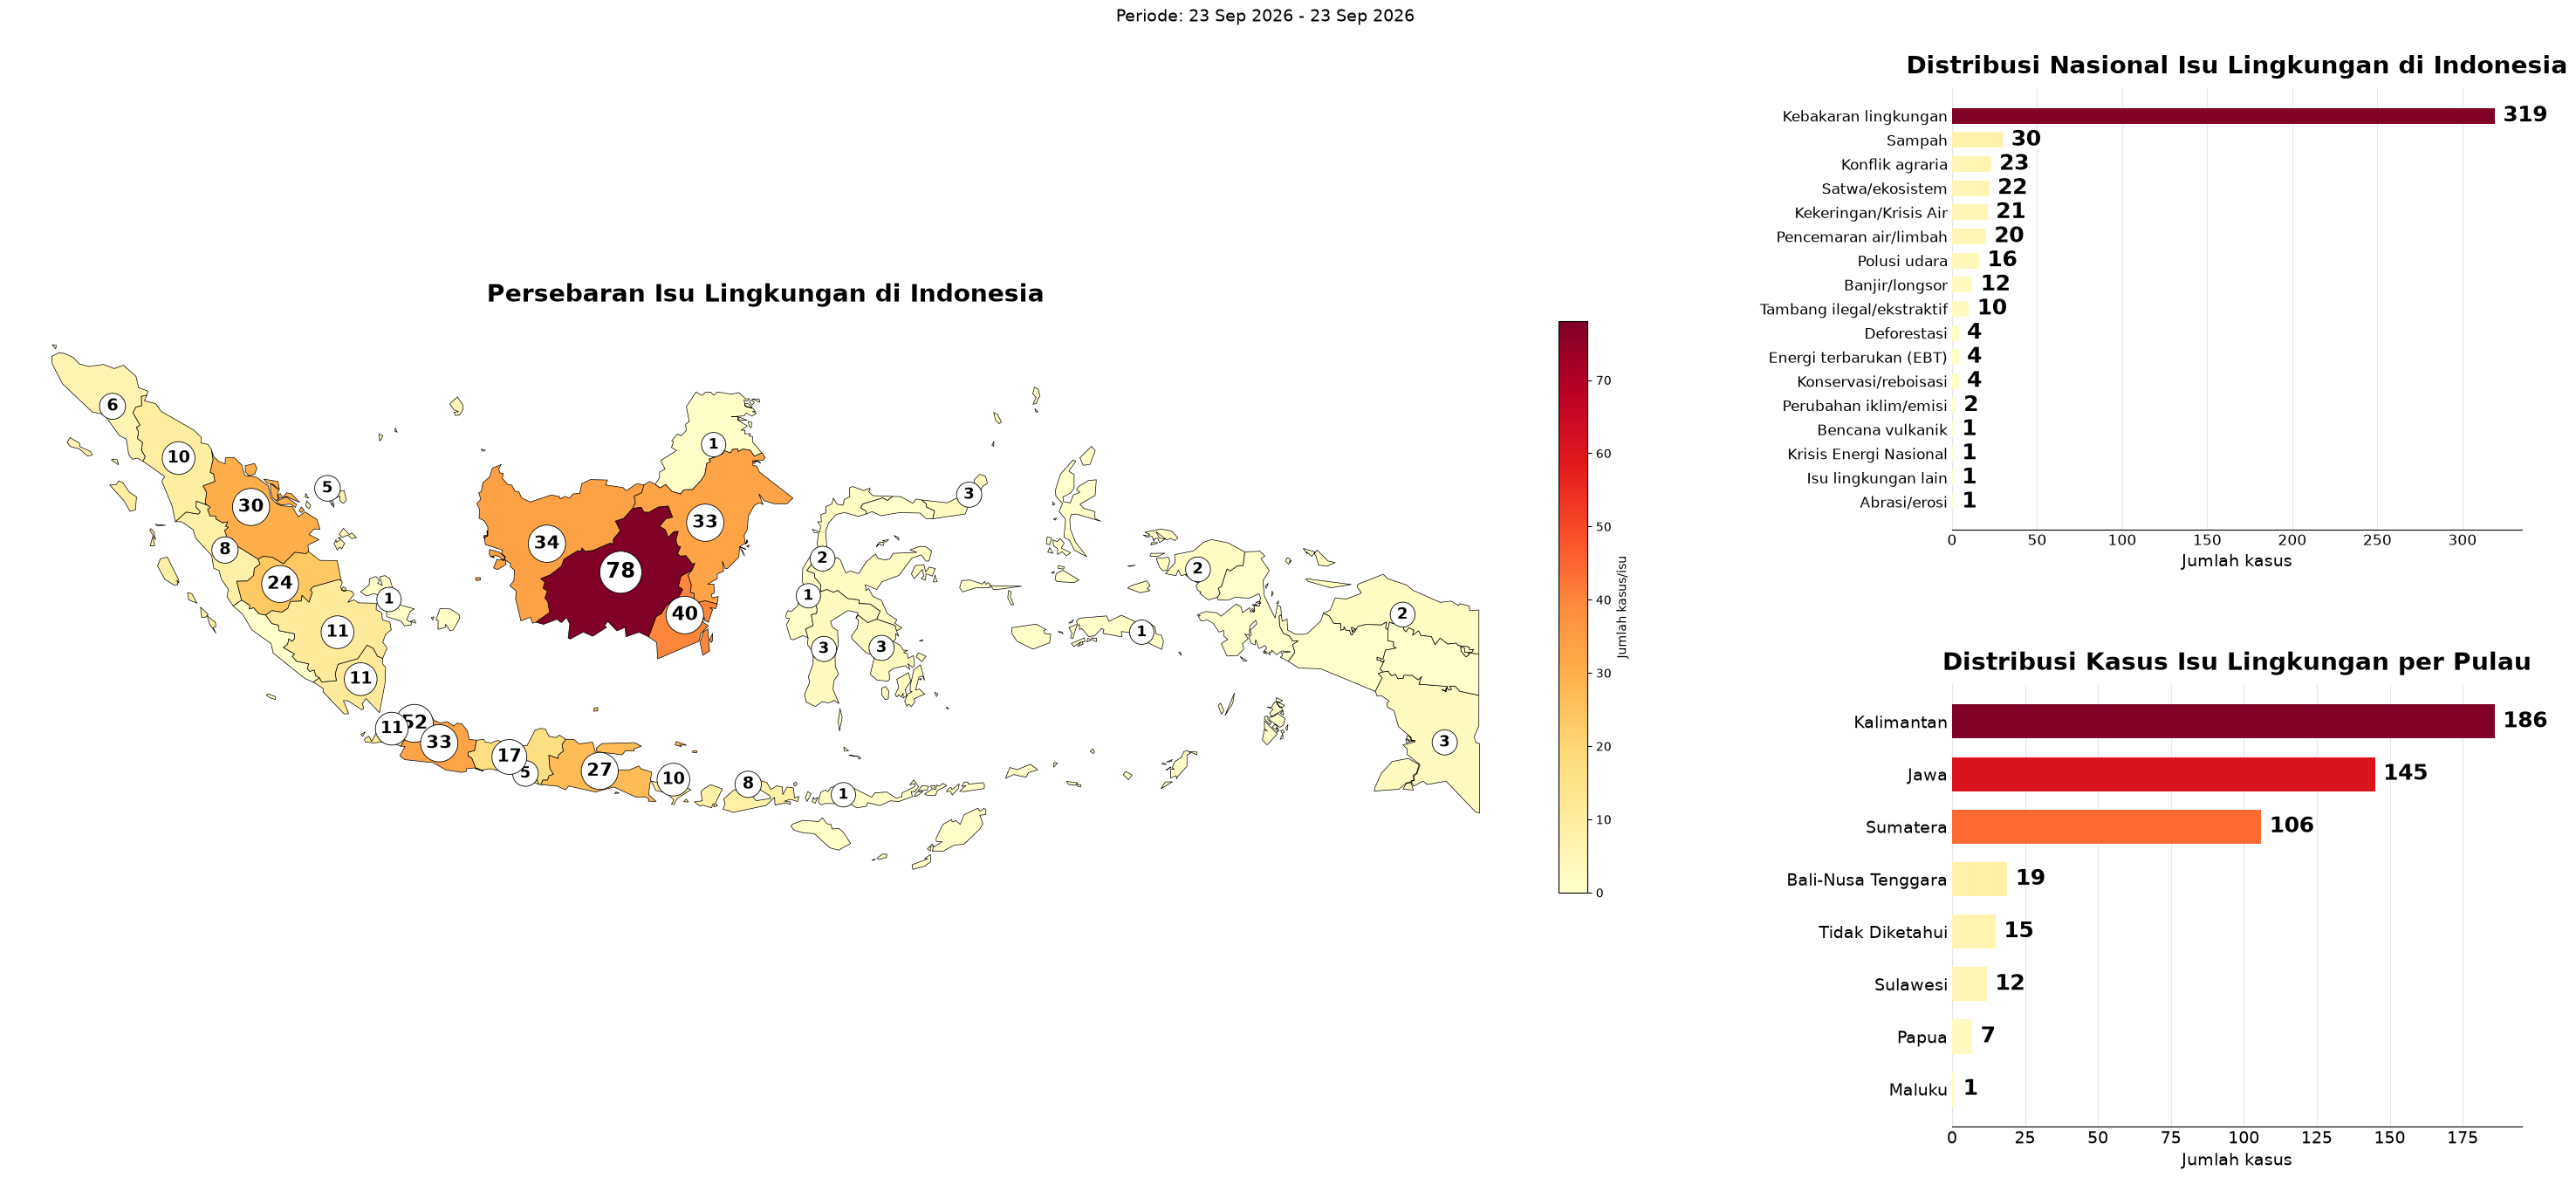

In [6]:
def prepare_data(data: pd.DataFrame):
    data = data.copy()

    data['Date'] = pd.to_datetime(data['Date'], format='ISO8601', errors='coerce').dt.normalize()

    if 'Sentiment' in data.columns:
        data['Sentiment'] = data['Sentiment'].astype(str).str.strip().str.lower()

    data = data.sort_values('Date', ascending=True, na_position='last').reset_index(drop=True)

    valid_dates = data['Date'].dropna()
    if valid_dates.empty:
        start_date = end_date = "Periode tidak diketahui"
    else:
        start_date = valid_dates.iloc[0].strftime('%d %b %Y')
        end_date = valid_dates.iloc[-1].strftime('%d %b %Y')

    return data, start_date, end_date


def _format_period(start, end):
    return f"{start} - {end}"


CMAP_NAME = "YlOrRd"

GEOJSON_PATH = "indonesia_38_provinsi.geojson"
GEOJSON_URL = (
    "https://raw.githubusercontent.com/denyherianto/"
    "indonesia-geojson-topojson-maps-with-38-provinces/main/"
    "GeoJSON/indonesia-38-provinces.geojson"
)
EXPECTED_PROVINCE_COUNT = 38

MANUAL_BADGE_POSITION = {
    "KEPULAUAN RIAU": (104.05, 1.30),
    "BALI": (115.15, -8.05),
    "NUSA TENGGARA BARAT": (117.55, -8.20),
}


# ---------------------------------------------------------
# HELPER: NORMALISASI NAMA PROVINSI (pakai fix dari great)
# ---------------------------------------------------------
def _build_ci_map(mapping: dict) -> dict:
    """Versi case-insensitive dari PROVINCE_FIX/GEO_FIX — key & value string
    diseragamkan ke UPPERCASE supaya cocok dengan alur .upper() di script ini."""
    out = {}
    for k, v in mapping.items():
        key = " ".join(str(k).strip().upper().split())
        if isinstance(v, str):
            out[key] = " ".join(v.strip().upper().split())
        else:
            out[key] = v  # np.nan tetap np.nan
    return out

PROVINCE_FIX_CI = _build_ci_map(PROVINCE_FIX)  # untuk kolom "Provinsi" di data
GEO_FIX_CI = _build_ci_map(GEO_FIX)            # untuk kolom nama provinsi di GeoJSON

PULAU_MAP_CI = {str(k).strip().upper(): v for k, v in PULAU_MAP.items()}
PULAU_MAP_CI["GENERAL SELURUH INDONESIA"] = "General Seluruh Indonesia"
PULAU_MAP_CI["PROVINSI TIDAK SPESIFIK"] = "Tidak Diketahui"

def _normalize_name(name, fixes: dict) -> str:
    key = " ".join(str(name).strip().upper().split())
    fixed = fixes.get(key, key)
    return "TIDAK DIKETAHUI" if pd.isna(fixed) else fixed

def _normalize_data_name(name) -> str:
    """Nama provinsi dari kolom data (survei/scrape)."""
    return _normalize_name(name, PROVINCE_FIX_CI)

def _normalize_geo_name(name) -> str:
    """Nama provinsi dari kolom GeoJSON."""
    return _normalize_name(name, GEO_FIX_CI)

def _detect_province_column(map_gdf: gpd.GeoDataFrame):
    possible_columns = [
        "Provinsi", "Propinsi", "PROVINSI", "PROPINSI",
        "NAME_1", "WADMPR", "provinsi", "name", "NAME",
    ]
    for column in possible_columns:
        if column in map_gdf.columns:
            return column
    return None


# ---------------------------------------------------------
# HELPER: PROVINSI -> PULAU (pakai PULAU_MAP dari great)
# ---------------------------------------------------------
def _get_island_aggs(data: pd.DataFrame) -> pd.Series:
    provinces = data["Provinsi"].apply(_normalize_data_name)
    islands = provinces.map(PULAU_MAP_CI)

    unmapped_mask = islands.isna()
    if unmapped_mask.any():
        unmapped_provinces = sorted(provinces[unmapped_mask].unique().tolist())
        print(f"[WARNING] {unmapped_mask.sum()} baris provinsi tidak punya mapping pulau "
              f"dan akan diabaikan di chart per pulau: {unmapped_provinces}")

    return islands.value_counts().sort_values(ascending=True)


# ---------------------------------------------------------
# HELPER: DOWNLOAD / LOAD GEOJSON
# ---------------------------------------------------------
def _load_geojson() -> gpd.GeoDataFrame:
    def _download():
        try:
            response = requests.get(GEOJSON_URL, timeout=30)
            response.raise_for_status()
            with open(GEOJSON_PATH, "wb") as file:
                file.write(response.content)
            return True
        except Exception as error:
            print("[ERROR] Gagal download GeoJSON:", error)
            return False

    if not os.path.exists(GEOJSON_PATH):
        if not _download():
            return gpd.GeoDataFrame()

    try:
        map_gdf = gpd.read_file(GEOJSON_PATH)
    except Exception as error:
        print("[ERROR] Gagal membaca GeoJSON:", error)
        return gpd.GeoDataFrame()

    if len(map_gdf) != EXPECTED_PROVINCE_COUNT:
        os.remove(GEOJSON_PATH)
        if not _download():
            return gpd.GeoDataFrame()
        try:
            map_gdf = gpd.read_file(GEOJSON_PATH)
        except Exception as error:
            print("[ERROR] Gagal membaca GeoJSON setelah redownload:", error)
            return gpd.GeoDataFrame()

        if len(map_gdf) != EXPECTED_PROVINCE_COUNT:
            print(f"[WARNING] Jumlah provinsi di GeoJSON ({len(map_gdf)}) masih tidak sesuai "
                  f"ekspektasi ({EXPECTED_PROVINCE_COUNT}) setelah redownload. Lanjut pakai data ini.")

    return map_gdf


# ---------------------------------------------------------
# HELPER: AGREGASI JUMLAH KASUS
# ---------------------------------------------------------
def _get_aggs(data: pd.DataFrame) -> pd.DataFrame:
    if "Provinsi" not in data.columns:
        print("[ERROR] Kolom 'Provinsi' tidak ditemukan pada dataset.")
        return pd.DataFrame(columns=["provinsi_normalized", "jumlah_kasus"])

    # Normalisasi dulu, baru groupby — supaya varian nama yang berbeda tapi
    # normalize ke provinsi yang sama tidak menghasilkan baris duplikat
    # (duplikat itu bisa gandakan baris saat merge ke map_gdf).
    normalized = data["Provinsi"].apply(_normalize_data_name)
    aggs = (
        normalized
        .value_counts()
        .rename("jumlah_kasus")
        .rename_axis("provinsi_normalized")
        .reset_index()
    )
    return aggs


# ---------------------------------------------------------
# HELPER: MENYIAPKAN GEODATAFRAME (peta + jumlah kasus)
# ---------------------------------------------------------
def _get_map_gdf(data: pd.DataFrame) -> gpd.GeoDataFrame:
    map_gdf = _load_geojson()
    if map_gdf.empty:
        print("[ERROR] GeoJSON kosong.")
        return gpd.GeoDataFrame()

    prov_col = _detect_province_column(map_gdf)
    if prov_col is None:
        print("[ERROR] Kolom nama provinsi tidak ditemukan pada GeoJSON.")
        return gpd.GeoDataFrame()

    map_gdf["provinsi_normalized"] = map_gdf[prov_col].apply(_normalize_geo_name)

    dup_geo = map_gdf["provinsi_normalized"].duplicated(keep=False)
    if dup_geo.any():
        print(f"[WARNING] GeoJSON punya {dup_geo.sum()} baris dengan nama provinsi "
              f"terduplikasi setelah normalisasi: "
              f"{sorted(map_gdf.loc[dup_geo, 'provinsi_normalized'].unique().tolist())}")

    aggs = _get_aggs(data)

    map_gdf = map_gdf.merge(
        aggs[["provinsi_normalized", "jumlah_kasus"]],
        on="provinsi_normalized",
        how="left",
        validate="m:1",  # akan raise MergeError kalau ternyata masih ada duplikat di aggs
    )
    map_gdf["jumlah_kasus"] = map_gdf["jumlah_kasus"].fillna(0)

    return map_gdf


# ---------------------------------------------------------
# HELPER: TITIK UTAMA PROVINSI
# ---------------------------------------------------------
def _main_point(geometry):
    if isinstance(geometry, MultiPolygon):
        largest_polygon = max(geometry.geoms, key=lambda geom: geom.area)
        return largest_polygon.representative_point()
    return geometry.representative_point()


def _badge_xy(row, prov_col):
    """Posisi angka di peta: manual untuk provinsi kecil, selain itu titik di pulau terbesar."""
    province = _normalize_geo_name(row[prov_col])
    if province in MANUAL_BADGE_POSITION:
        return MANUAL_BADGE_POSITION[province]
    point = _main_point(row.geometry)
    return point.x, point.y


def _barh_with_labels(ax, counts: pd.Series, title: str, labelsize: int):
    """Bar chart horizontal, warna mengikuti nilai, angka di ujung bar."""
    max_value = counts.max()
    colors = plt.colormaps[CMAP_NAME]([v / max_value for v in counts.values])
    bars = ax.barh(counts.index, counts.values, color=colors, height=0.65)
    ax.set_title(title, fontsize=20, fontweight="bold", pad=12)
    ax.set_xlabel("Jumlah kasus", fontsize=14)
    ax.tick_params(labelsize=labelsize, length=0)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.xaxis.grid(True, alpha=0.3)
    ax.set_axisbelow(True)
    for bar in bars:
        width = bar.get_width()
        ax.text(width + max_value * 0.015, bar.get_y() + bar.get_height() / 2,
                f"{int(width)}", va="center", fontsize=18, fontweight="bold")


# ---------------------------------------------------------
# VISUAL GABUNGAN: HEADER + PETA (COLORBAR) + 2 BAR CHART
# ---------------------------------------------------------
def plot_dashboard(data: pd.DataFrame, start_date, end_date, report_date: str = None):
    fig = plt.figure(figsize=(30, 14))
    gs = fig.add_gridspec(2, 2, width_ratios=[3.2, 1], height_ratios=[1, 1], hspace=0.35, wspace=0.1)

    ax_map = fig.add_subplot(gs[:, 0])
    ax_nasional = fig.add_subplot(gs[0, 1])
    ax_pulau = fig.add_subplot(gs[1, 1])

    subtitle_parts = []
    if start_date is not None and end_date is not None:
        subtitle_parts.append(f"Periode: {start_date} - {end_date}")
    if report_date:
        subtitle_parts.append(f"Laporan: {report_date}")
    if subtitle_parts:
        fig.suptitle(" | ".join(subtitle_parts), fontsize=14, y=0.965)

    # --- PETA (dengan colorbar, badge proporsional) ---
    map_gdf = _get_map_gdf(data)
    if map_gdf.empty:
        print("[WARNING] Peta tidak dapat dirender.")
    else:
        prov_col = _detect_province_column(map_gdf)

        map_gdf.plot(
            column="jumlah_kasus", cmap=CMAP_NAME, linewidth=0.5, edgecolor="black",
            ax=ax_map, legend=True,
            legend_kwds={"label": "Jumlah kasus/isu", "shrink": 0.55, "pad": 0.02},
            missing_kwds={"color": "#d9d9d9", "edgecolor": "black", "linewidth": 0.5},
        )

        minx, miny, maxx, maxy = map_gdf.total_bounds
        pad_x, pad_y = (maxx - minx) * 0.03, (maxy - miny) * 0.05
        ax_map.set_xlim(minx - pad_x, maxx + pad_x)
        ax_map.set_ylim(miny - pad_y, maxy + pad_y)
        ax_map.set_aspect("equal")

        max_value = map_gdf["jumlah_kasus"].max()
        if pd.isna(max_value) or max_value <= 0:
            max_value = 1

        for _, row in map_gdf.iterrows():
            value = row["jumlah_kasus"]
            if pd.isna(value) or value <= 0:
                continue

            x, y = _badge_xy(row, prov_col)
            scale = (value / max_value) ** 0.5
            font_size = 12 + scale * 5

            ax_map.text(
                x, y, f"{int(value)}", ha="center", va="center", zorder=10,
                fontsize=font_size, fontweight="bold", color="black",
                bbox=dict(boxstyle="circle,pad=0.3", facecolor="white",
                          edgecolor="black", linewidth=0.6),
            )

        ax_map.set_title("Persebaran Isu Lingkungan di Indonesia", fontsize=20, fontweight="bold", pad=14)
        ax_map.axis("off")

    # --- BAR CHART NASIONAL ---
    if "Isu_Inti" in data.columns and data["Isu_Inti"].dropna().shape[0] > 0:
        counts = data["Isu_Inti"].value_counts().sort_values(ascending=True)
        _barh_with_labels(ax_nasional, counts, "Distribusi Nasional Isu Lingkungan di Indonesia", labelsize=12)
    else:
        print("[WARNING] Kolom 'Isu_Inti' tidak ada atau kosong, chart nasional dilewati.")
        ax_nasional.axis("off")

    # --- BAR CHART PER PULAU ---
    if "Provinsi" in data.columns:
        island_counts = _get_island_aggs(data)
        if island_counts.shape[0] > 0:
            _barh_with_labels(ax_pulau, island_counts, "Distribusi Kasus Isu Lingkungan per Pulau", labelsize=14)
        else:
            print("[WARNING] Tidak ada data pulau yang bisa dipetakan, chart per pulau dilewati.")
            ax_pulau.axis("off")
    else:
        ax_pulau.axis("off")

    plt.subplots_adjust(left=0.02, right=0.98, top=0.9, bottom=0.05)
    plt.show()
    return fig

df_clean, start_date, end_date = prepare_data(df_clean)
df_visual = df_clean[(df_clean["Isu_Inti"] != "Noise/Tidak Relevan")
            & (df_clean["Pulau"] != "General Seluruh Indonesia") ].reset_index(drop=True)

fig = plot_dashboard(df_visual, start_date, end_date)

# CELL 6 — DASHBOARD 2: peta + isu terbanyak dipecah per provinsi
Output: peta yang sama berdampingan dengan bar chart isu nasional. Bar isu teratas dipecah per provinsi supaya terlihat penyumbang terbesarnya.

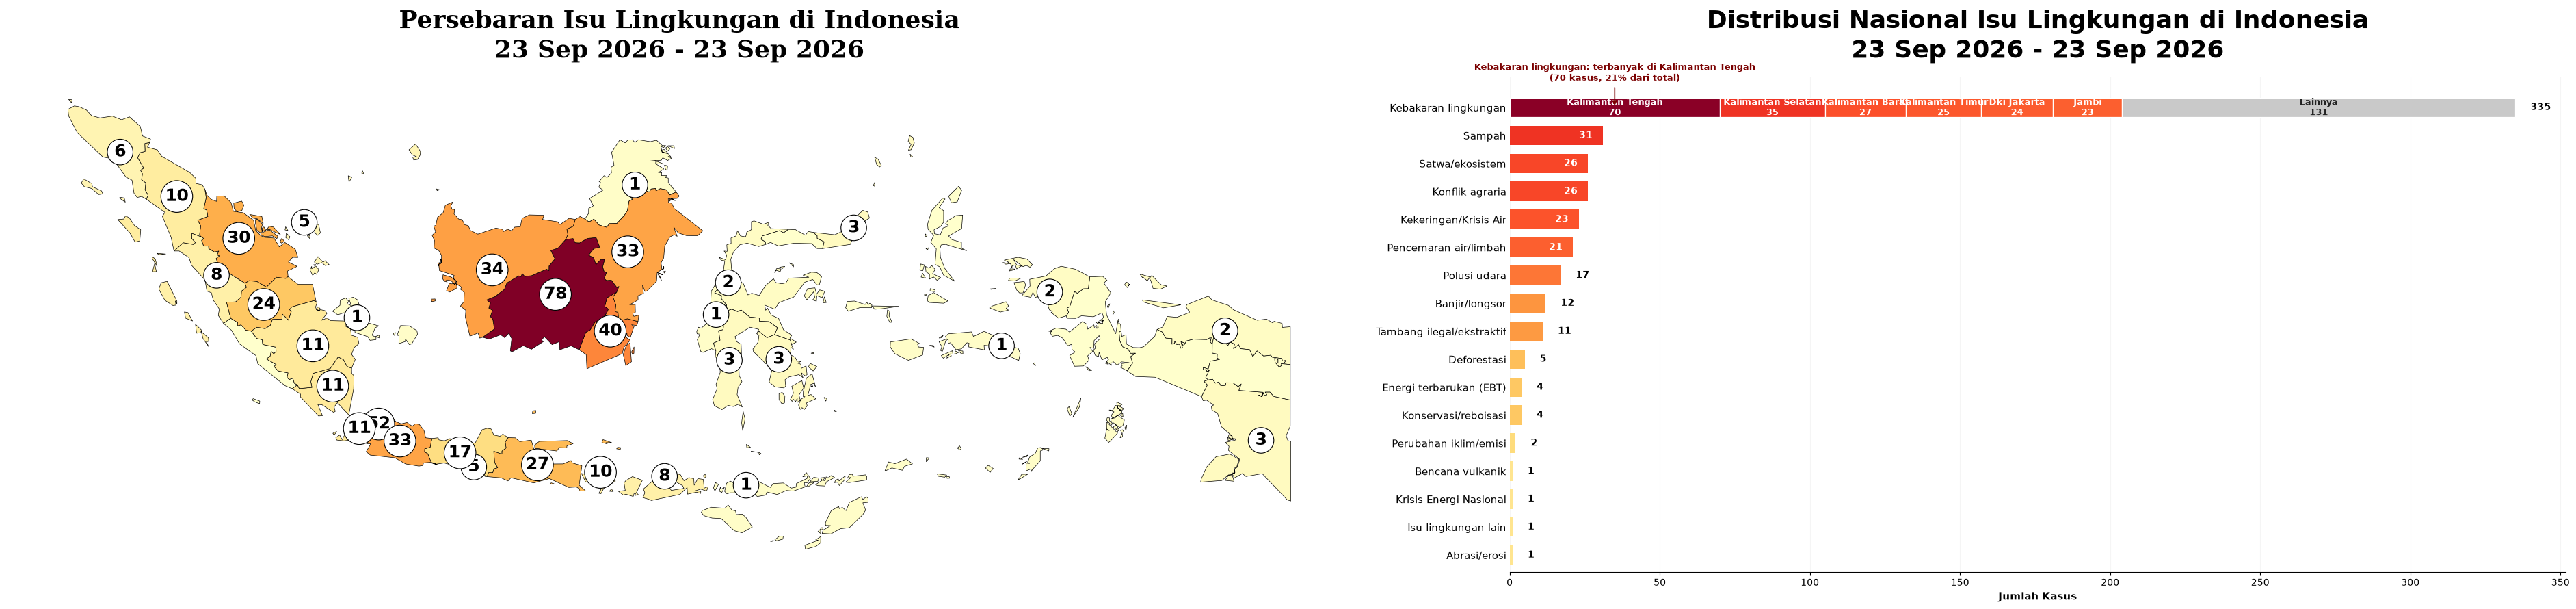

In [7]:
import matplotlib.colors as mcolors
from matplotlib.colors import PowerNorm

TITLE_SIZE = 26


def plot_combined(data: pd.DataFrame, start_date, end_date):
    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(38, 9),
        gridspec_kw={"width_ratios": [1.3, 1]}
    )

    # --- SUBPLOT 1 (KIRI): PETA CHOROPLETH INDONESIA ---
    map_gdf = _get_map_gdf(data)
    if map_gdf.empty:
        print("[WARNING] Peta tidak dapat dirender.")
        ax1.axis("off")
    else:
        prov_col = _detect_province_column(map_gdf)
        if prov_col is None:
            print("[ERROR] Kolom provinsi tidak ditemukan.")
            ax1.axis("off")
        else:
            map_gdf.plot(
                column="jumlah_kasus", cmap=CMAP_NAME, linewidth=0.5, edgecolor="black",
                ax=ax1, legend=False,
                missing_kwds={"color": "#ffffe0", "edgecolor": "black", "linewidth": 0.5},
            )

            def _draw_badge(x, y, value):
                ax1.text(
                    x, y, f"{int(value)}", ha="center", va="center", zorder=10,
                    fontsize=18, fontweight="bold", color="black",
                    bbox=dict(boxstyle="circle,pad=0.25", facecolor="white", edgecolor="black", linewidth=0.8),
                )

            for _, row in map_gdf.iterrows():
                value = row["jumlah_kasus"]
                if pd.isna(value) or value <= 0:
                    continue

                _draw_badge(*_badge_xy(row, prov_col), value)

            ax1.set_title(
                f"Persebaran Isu Lingkungan di Indonesia\n{_format_period(start_date, end_date)}",
                fontsize=TITLE_SIZE, fontweight="bold", family="serif", pad=20,
            )
            ax1.axis("off")

    # --- SUBPLOT 2 (KANAN): BAR CHART DISTRIBUSI ISU NASIONAL ---
    # Isu dengan jumlah kasus tertinggi dipecah (stacked) per provinsi,
    # supaya terlihat provinsi mana penyumbang terbesar dari isu tersebut.
    TOP_N_PROVINSI_DETAIL = 6  # provinsi individual yang ditampilkan; sisanya digabung "Lainnya"

    if "Isu_Inti" not in data.columns or data["Isu_Inti"].dropna().empty:
        print("[ERROR] Kolom 'Isu_Inti' tidak ditemukan atau kosong.")
        ax2.axis("off")
    else:
        counts = data["Isu_Inti"].value_counts().sort_values(ascending=True)
        top_issue = counts.index[-1]
        max_value = counts.max()

        cmap = plt.get_cmap(CMAP_NAME)
        map_max = map_gdf["jumlah_kasus"].max() if not map_gdf.empty else max_value
        if pd.isna(map_max) or map_max <= 0:
            map_max = max_value if max_value > 0 else 1
        norm = PowerNorm(gamma=0.4, vmin=0, vmax=map_max)

        y_positions = list(range(len(counts)))
        top_y = y_positions[-1]

        # --- bar biasa (semua isu selain isu tertinggi) ---
        for y_pos, isu in zip(y_positions, counts.index):
            if isu == top_issue:
                continue
            value = counts[isu]
            color = cmap(norm(value))
            ax2.barh(y_pos, value, color=color, height=0.7)

            is_dark = norm(value) > 0.55
            text_color = "white" if is_dark else "black"
            text_x = value - max_value * 0.01 if is_dark else value + max_value * 0.015
            ha = "right" if is_dark else "left"
            ax2.text(
                text_x, y_pos, f"{int(value)}", va="center", ha=ha,
                fontsize=10, fontweight="bold", color=text_color,
            )

        # --- bar isu tertinggi: dipecah per provinsi (stacked + gradasi) ---
        UNDETECTED_LABEL = "TIDAK DIKETAHUI"  # sesuai output _normalize_data_name

        subset_top = data.loc[data["Isu_Inti"] == top_issue, "Provinsi"].dropna() if "Provinsi" in data.columns else pd.Series(dtype=object)

        if subset_top.empty:
            value = counts[top_issue]
            ax2.barh(top_y, value, color=cmap(norm(value)), height=0.7)
            ax2.text(value + max_value * 0.015, top_y, f"{int(value)}", va="center",
                      fontsize=10, fontweight="bold", color="black")
        else:
            # pakai _normalize_data_name konsisten dengan _get_aggs/_get_island_aggs
            prov_counts_raw = subset_top.apply(_normalize_data_name).value_counts().sort_values(ascending=False)

            prov_counts = prov_counts_raw[prov_counts_raw.index != UNDETECTED_LABEL]
            undetected_count = prov_counts_raw.get(UNDETECTED_LABEL, 0)

            if prov_counts.empty:
                # semua baris gagal normalize — fallback ke bar polos, hindari IndexError di bawah
                value = counts[top_issue]
                ax2.barh(top_y, value, color=cmap(norm(value)), height=0.7)
                ax2.text(value + max_value * 0.015, top_y, f"{int(value)}", va="center",
                          fontsize=10, fontweight="bold", color="black")
            else:
                if len(prov_counts) > TOP_N_PROVINSI_DETAIL:
                    prov_display = prov_counts.iloc[:TOP_N_PROVINSI_DETAIL].copy()
                    lainnya_total = prov_counts.iloc[TOP_N_PROVINSI_DETAIL:].sum() + undetected_count
                else:
                    prov_display = prov_counts.copy()
                    lainnya_total = undetected_count

                if lainnya_total > 0:
                    prov_display["Lainnya"] = lainnya_total

                total_top = prov_display.sum()
                max_seg = prov_counts.iloc[0]
                left = 0.0
                for prov, val in prov_display.items():
                    if prov == "Lainnya":
                        seg_color = "#c9c9c9"
                        shade = 0.0
                    else:
                        shade = 0.40 + 0.58 * (val / max_seg)
                        seg_color = cmap(shade)

                    ax2.barh(top_y, val, left=left, color=seg_color, height=0.7,
                              edgecolor="white", linewidth=0.9)

                    frac = val / total_top
                    if frac > 0.03:
                        is_dark = shade > 0.55
                        txt_color = "white" if is_dark else "#222222"
                        display_name = prov if prov == "Lainnya" else prov.title()
                        label = f"{display_name}\n{int(val)}" if frac > 0.05 else f"{int(val)}"
                        ax2.text(left + val / 2, top_y, label, ha="center", va="center",
                                  fontsize=9 if frac > 0.05 else 7.5, fontweight="bold", color=txt_color)
                    left += val

                ax2.text(left + max_value * 0.015, top_y, f"{int(total_top)}", va="center",
                          fontsize=10, fontweight="bold", color="black")

                top_prov_name = prov_counts.index[0].title()
                top_prov_val = int(prov_counts.iloc[0])
                top_prov_pct = top_prov_val / total_top * 100
                ax2.annotate(
                    f"{top_issue}: terbanyak di {top_prov_name}\n({top_prov_val} kasus, {top_prov_pct:.0f}% dari total)",
                    xy=(top_prov_val / 2, top_y), xytext=(top_prov_val / 2, top_y + 0.85),
                    ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#7a0000",
                    arrowprops=dict(arrowstyle="-|>", color="#7a0000", lw=1.2),
                )

        ax2.set_title(
            f"Distribusi Nasional Isu Lingkungan di Indonesia\n{_format_period(start_date, end_date)}",
            fontsize=TITLE_SIZE, fontweight="bold", pad=20,
        )
        ax2.set_xlabel("Jumlah Kasus", fontsize=11, fontweight="bold")
        ax2.set_yticks(y_positions)
        ax2.set_yticklabels(counts.index)
        ax2.set_ylim(-0.6, top_y + 1.1)
        ax2.tick_params(axis="y", labelsize=11, length=0)
        ax2.spines[["top", "right", "left"]].set_visible(False)
        ax2.xaxis.grid(True, linestyle="-", alpha=0.3, color="#e0e0e0")
        ax2.set_axisbelow(True)

    plt.tight_layout()
    plt.show()
    return fig


# df_clean sudah lewat prepare_data di CELL 5
df_visual = df_clean[df_clean["Isu_Inti"] != "Noise/Tidak Relevan"].reset_index(drop=True)
fig_combined = plot_combined(df_visual, start_date, end_date)

# CELL 7 — TABEL: TOP ISU PER PULAU (Berita) & TOP ISU MEDIA SOSIAL
Output: 5 pulau dengan berita terbanyak (2 isu teramai per pulau, maks. 5 link per isu) dan 5 isu teramai di media sosial beserta contoh link.

In [8]:
df_berita = df_clean[df_clean["Tipe_Link"] == "Berita"]

top5_pulau = (
    df_berita[~df_berita["Pulau"].isin(["General Seluruh Indonesia"])]
    .groupby("Pulau").size().sort_values(ascending=False).head(5).index.tolist()
)

berita_rows = []
for pulau in top5_pulau:
    subset = df_berita[df_berita["Pulau"] == pulau]
    top2_isu = subset["Isu_Inti"].value_counts().head(2)
    for isu, jumlah_isu in top2_isu.items():
        links = subset[subset["Isu_Inti"] == isu]["Link"].head(5).tolist()
        for link in links:
            berita_rows.append({"Pulau": pulau, "Isu": isu, "Jumlah Berita (Isu)": jumlah_isu, "Link": link})

berita_table = pd.DataFrame(berita_rows)
print("BERITA — 5 PULAU TERATAS, 2 ISU TERAMAI PER PULAU:")
display(berita_table)

df_medsos = df_clean[df_clean["Tipe_Link"] == "Media Sosial"]
top5_isu_medsos = df_medsos["Isu_Inti"].value_counts().head(5)

medsos_rows = []
for isu, jumlah_isu in top5_isu_medsos.items():
    links = df_medsos[df_medsos["Isu_Inti"] == isu]["Link"].head(5).tolist()
    for link in links:
        medsos_rows.append({"Isu": isu, "Jumlah Postingan (Isu)": jumlah_isu, "Link": link})

medsos_table = pd.DataFrame(medsos_rows)
print("\nMEDIA SOSIAL — 5 ISU TERAMAI:")
display(medsos_table)

BERITA — 5 PULAU TERATAS, 2 ISU TERAMAI PER PULAU:


,Pulau,Isu,Jumlah Berita (Isu),Link
0,Kalimantan,Kebakaran lingkungan,137,https://kaltengonline.com/2026/09/23/lpbi-nu-p...
1,Kalimantan,Kebakaran lingkungan,137,https://pontianak.tribunnews.com/kalbar/118709...
2,Kalimantan,Kebakaran lingkungan,137,https://ameera.republika.co.id/berita/tlsq3j42...
3,Kalimantan,Kebakaran lingkungan,137,https://kalimantanlive.com/2026/09/23/54-situs...
4,Kalimantan,Kebakaran lingkungan,137,https://prokalteng.jawapos.com/pemerintahan/pe...
5,Kalimantan,Polusi udara,6,https://totabuan.news/terkini/polusi-akibat-ka...
6,Kalimantan,Polusi udara,6,https://health.detik.com/berita-detikhealth/d-...
7,Kalimantan,Polusi udara,6,https://katadata.co.id/berita/nasional/6ab325c...
8,Kalimantan,Polusi udara,6,https://www.metrotvnews.com/read/KZmCQEQQ-klh-...
9,Kalimantan,Polusi udara,6,https://www.bloombergtechnoz.com/detail-news/1...



MEDIA SOSIAL — 5 ISU TERAMAI:


,Isu,Jumlah Postingan (Isu),Link
0,Kebakaran lingkungan,54,https://twitter.com/web/statuses/2102681553247...
1,Kebakaran lingkungan,54,https://www.youtube.com/watch?v=jFbSeYtQXQo
2,Kebakaran lingkungan,54,https://www.youtube.com/watch?v=XKbjNNtLYwY
3,Kebakaran lingkungan,54,https://www.youtube.com/watch?v=faqk6TUfCf0
4,Kebakaran lingkungan,54,https://www.youtube.com/watch?v=Mp8hiZQSepc
5,Polusi udara,4,https://www.youtube.com/watch?v=tfm9JCL34iY
6,Polusi udara,4,https://www.youtube.com/watch?v=yP2xzq8XcIU
7,Polusi udara,4,https://www.youtube.com/watch?v=l8IL6vAv1YU
8,Polusi udara,4,https://www.youtube.com/watch?v=cOkM6dJZwyg
9,Sampah,2,https://www.youtube.com/watch?v=mU9SwOm2y3E


# QA: DOKUMEN YANG TIDAK TERKLASIFIKASI (isu / lokasi)
Untuk pengembangan, bukan laporan. Output: kata/frasa yang sering muncul di dokumen tanpa lokasi Indonesia, nama daerah yang belum dikenali resolver, dan kandidat kata kunci *noise* asing baru. Semua perlu dicek manual sebelum dipakai.

In [9]:
STOPWORDS_ID = set("""
yang di ke dari dan atau untuk pada dengan dalam ini itu adalah akan telah
sudah tidak juga karena oleh sebagai atas dapat bisa saat ketika para
antara namun tetapi jika kata ada tahun hari lalu kemarin sebut ujar
dia mereka kami kita saya anda tersebut baik serta hingga sekitar
lebih dua satu tiga bagi setelah sejak selama menjadi terkait
""".split())


def top_terms(texts, n=40, ngram=1):
    """Kata (ngram=1) atau frasa (ngram=2) paling sering, tanpa stopword."""
    counter = Counter()
    for text in texts:
        words = [w for w in re.findall(r"\b[a-z]{3,}\b", str(text).lower()) if w not in STOPWORDS_ID]
        counter.update(" ".join(g) for g in zip(*[words[i:] for i in range(ngram)]))
    return counter.most_common(n)


general_subset = df_clean[df_clean["Pulau"] == "General Seluruh Indonesia"]

# ------------------------------------------------------------------
# 1. KANDIDAT ISU / NOISE
#    Baris General yang Isu_Inti-nya BUKAN "Noise/Tidak Relevan" —
#    berarti lolos ISSUE_RULES padahal kandidat noise (geo-gate belum
#    nangkep, atau kata pemicu isu ISSUE_RULES ke-trigger tanpa konteks
#    Indonesia).
# ------------------------------------------------------------------
suspect_noise = general_subset[general_subset["Isu_Inti"] != "Noise/Tidak Relevan"]
print(f"Kandidat noise yang lolos jadi isu valid: {len(suspect_noise)} baris\n")

known_noise_words = {w.lower() for w in FOREIGN_NOISE_KEYWORDS}

print("Top kata (kandidat baru FOREIGN_NOISE_KEYWORDS / exclude ISSUE_RULES):")
for w, c in top_terms(suspect_noise["search_text"], n=30, ngram=1):
    if w not in known_noise_words:
        print(f"  {w}: {c}")

print("\nTop frasa 2 kata:")
for p, c in top_terms(suspect_noise["search_text"], n=20, ngram=2):
    if not any(word in known_noise_words for word in p.split()):
        print(f"  {p}: {c}")

sample = suspect_noise.sample(min(15, len(suspect_noise)), random_state=1)
print("\nSample baca manual (konfirmasi konteks, bukan cuma kata kunci lepas):")
for i, row in sample.iterrows():
    print(f"--- {i} | {row['Isu_Inti']} ---")
    print(str(row['Mentions'])[:200])
    print()

# ------------------------------------------------------------------
# 2. KANDIDAT LOKASI
#    Baris General yang teksnya ADA pola "Kabupaten/Kota/Kec./Provinsi X"
#    tapi resolve_frame gagal cocokin -> X belum ada di gazetteer great.geo.
#    Dikumpulin per-nama + frekuensi, bukan raw list 30 baris pertama —
#    biar nama yang sering muncul kelihatan duluan, bukan urutan index.
# ------------------------------------------------------------------
loc_pattern = re.compile(
    r'\b(?:kabupaten|kota|kec\.|kecamatan|provinsi)\s+([a-z]+(?:\s+[a-z]+)?)',
    re.IGNORECASE,
)

loc_candidates = Counter()
loc_examples = {}
for idx, txt in general_subset["Mentions"].dropna().items():
    for name in loc_pattern.findall(str(txt)):
        key = name.strip().lower()
        loc_candidates[key] += 1
        loc_examples.setdefault(key, (idx, str(txt)[:200]))

print(f"\nKandidat nama daerah belum ke-gazetteer: {len(loc_candidates)} nama unik, "
      f"{sum(loc_candidates.values())} total kemunculan\n")
for name, count in loc_candidates.most_common(30):
    idx, snippet = loc_examples[name]
    print(f"{name} ({count}x) — contoh DOC index {idx}:\n  {snippet}\n")

# ------------------------------------------------------------------
# 3. KANDIDAT FOREIGN_NOISE_KEYWORDS
#    Proper noun (Title Case di teks asli, sebelum di-lowercase) yang
#    sering muncul di suspect_noise tapi belum ke-cover FOREIGN_NOISE_KEYWORDS.
#    Heuristik kapitalisasi doang, BUKAN cek gazetteer -> tetap wajib
#    direview manual sebelum ditambah ke list resmi (nama orang Indonesia,
#    nama media, nama institusi lokal bisa ikut ke-tangkep juga).
# ------------------------------------------------------------------
PROPER_NOUN_PATTERN = re.compile(r'\b[A-Z][a-zA-Z]{2,}\b')
COMMON_CAPITALIZED_NOISE = {
    "Indonesia", "Presiden", "Menteri", "Pemerintah", "Foto", "Sumber",
    "ANTARA", "REPUBLIKA", "KOMPAS", "Dok",
}

proper_noun_counts = Counter()
for txt in suspect_noise["Mentions"].dropna():
    words = PROPER_NOUN_PATTERN.findall(str(txt))
    proper_noun_counts.update(
        w for w in words
        if w not in COMMON_CAPITALIZED_NOISE and w.lower() not in known_noise_words
    )

print("\nKandidat FOREIGN_NOISE_KEYWORDS baru (review manual dulu sebelum dipakai):")
for name, count in proper_noun_counts.most_common(30):
    print(f"  {name}: {count}")

Kandidat noise yang lolos jadi isu valid: 30 baris

Top kata (kandidat baru FOREIGN_NOISE_KEYWORDS / exclude ISSUE_RULES):
  logistik: 58
  kebakaran: 55
  hutan: 48
  karhutla: 44
  api: 43
  masyarakat: 37
  lahan: 35
  kontainer: 33
  terhadap: 30
  lingkungan: 30
  kai: 30
  jalan: 26
  kereta: 24
  kesehatan: 21
  melalui: 21
  layanan: 21
  air: 20
  rata: 20
  semakin: 19
  hanya: 18
  indonesia: 18
  udara: 17
  sekaligus: 17
  sangat: 16
  besar: 16
  perusahaan: 16
  terus: 16
  bahwa: 15
  memberikan: 15
  volume: 15

Top frasa 2 kata:
  kebakaran hutan: 33
  kai logistik: 30
  kereta api: 24
  hutan lahan: 16
  jalan raya: 12
  lahan karhutla: 11
  rata rata: 10
  sangat pal: 7
  kota bangun: 7
  reaksi bule: 6
  bukan hanya: 6
  angkutan kontainer: 6
  logistik berkelanjutan: 6
  api logistik: 6
  logistik kai: 6
  logistik terus: 6
  terus memperkuat: 6
  sekaligus mendukung: 6
  sejumlah inisiatif: 6
  kontainer mencapai: 6

Sample baca manual (konfirmasi konteks, bukan 